# KQC DemoTwoface — the Demo chip split over two faces (flip chip) (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/demo_twoface.py` (class `DemoTwoface`, default parameters, chip name
"DT"; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`third_party/KQCircuits/klayout_package/python/kqcircuits/chips/demo_twoface.py`; spec
`docs/designs/kqc/demo_twoface.md`). Four Swissmons on the bottom chip (face 0, `1t1`) at (2000 | 8000,
3200 | 6800) µm, with two straight buses (QB1–QB2, QB4–QB3; a = 4, b = 9 µm) and a charge and a flux line per
qubit from an ARD24 sample holder. Each readout leaves the qubit's coupler 1 on the bottom chip, crosses to the
top chip (face 1, `2b1`) through a flip-chip RF connector, meanders there and couples through a finger capacitor
and a T into one of two probe lines that also run on the top chip (probe line 1 serves QB1 and QB3, probe line 2
QB2 and QB4). The probe lines leave the top chip through an RF connector each way to the bottom-chip launchers.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` on both faces (top-chip box (1500, 1500)–(8500, 8500) µm) | same 10 × 10 mm (ARD24 launchers on its edges); Quantcore die frame on the bottom chip only — PDK v3 defines no frame for the flip-chip top chip (its layers export to 800–804/0); device ID "DT" |
| launchers | ARD24, `launcher_indent` 680 µm (outer etch 21 µm from the edge) | ARD24, indent **759 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm); same 12-pad assignment |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed 15–18 nH) | Quantcore trilayer SQUIDs **detuned on purpose** by the straight finger: 0.27 / 0.26 / 0.25 / 0.24 µm → R_n 41.7 / 43.3 / 45.0 / 46.9 kΩ (parallel), L_J 6.24 / 6.48 / 6.73 / 7.02 nH, so the bus-coupled pairs do not hybridise |
| cheese | KQC's whole-area ground grid (`with_grid`) | the same whole-area coverage with the PDK squares on the bottom chip (face 0): chip `cheese: "chip"` puts 5 µm squares with 20 µm gaps (instead of KQC's 5 µm on a 10 µm step) over the whole die, at least 4 µm from the 3/0 keep-outs and clear of the frame markers and the device ID; the top chip gets none (the build cheeses face 0 only) |
| elements, positions, routes | — | kept exactly; waypoints derived from the launcher ports |
| placement | centred | centred (checked, no shift) |

**Kept exactly (same KQC cells, parameters and positions):** the ARD24 launcher assignment (12 pads); the four
`Swissmon`s (coupler lengths 120 µm, port widths 4/10/4 µm) with KQC's rotation and mirror per qubit; the buses;
the charge lines (6 µm open end) and the flux lines (1500 µm past the launcher corner, then across); the readout
path (700 µm out of coupler 1, 400 µm sideways to the face change, 100 µm, then 1300 µm of meander on the top
chip) with the KQC total lengths 5000 … 5300 µm; the `FingerCapacitorSquare`s (7/6/5/4 fingers) and the
`WaveguideCoplanarSplitter` T's (lengths 11/11/41 µm) on the top chip; the `FingerCapacitorTaper` input
capacitors (4 and 6 fingers, 20 µm taper) 700 µm from the first T; the probe-line paths including their face
changes. The `FlipChipConnectorRf` cells are inserted by KQC's `WaveguideComposite` at the face-change nodes, as
in the source.

**Simplified:** the readout meanders are fitted by the router on the 1300 µm segment (KQC: a `Meander` with
`meanders=5` between the same two points; same length).

**Faces in the LOM and DRC:** the LOM is face-agnostic. The RF connector is part of its route, and the
capacitance of a line to the opposite chip comes only from a FEM C-matrix with both faces, which the exports do not do yet: they simulate the bottom chip only (Simulate 1).
The readouts end on a capacitor at both ends (coupler pad, finger capacitor), so they are λ/2 resonators
(≈ 11–12 GHz for 5 mm).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its ARD24 launchers, the launchers and the pad rule, the four qubits (first: the readout capacitors are placed from their ports), the top-chip readout capacitors, T's and probe lines, the four readouts with their face change, the two buses, the charge and flux lines, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `demo_twoface.v1.ipynb`; both save the same `demo_twoface.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/demo_twoface/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import junction_from_fingers

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/demo_twoface")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the qubits, the readout line,
the readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell with one
picture of the chip so far (both faces drawn; live, KLayout redraws after every cell).

**Why the qubits come before the readout line here.** KQC places each readout's finger capacitor by its port `a` at
the end of the readout path out of the qubit's coupler 1 (700 µm out, 500 µm sideways, 1300 µm further), the T on
the capacitor, the input capacitor 700 µm above the first T, and the probe lines through them: everything on the
readout line follows a qubit. The calls keep the v1's order; nothing is recomputed to put the line first. The PDK cheese (`cheese: "chip"`, ≈ 0.14 M holes over the bottom chip) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and KQC's ARD24 launcher assignment (twelve launchers) |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the qubits: four detuned Swissmons on the bottom chip |
| 4 | the readout line on the top chip: per qubit a finger capacitor and its T, the two input capacitors, the two probe lines (with their face changes) |
| 5 | the readout resonators: four λ/2 lines from coupler 1, crossing to the top chip |
| 6 | the coupling: two straight buses, QB1–QB2 and QB4–QB3 |
| 7 | the control routing: four charge lines and four flux lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the chip: the 10 × 10 mm box, the ARD24 launchers with KQC's DemoTwoface assignment (pad
numbers clockwise from the top-left; only the assigned ones are drawn) and the chip name "DT" (the device ID).
`cheese: "chip"` asks for the PDK cheese over the whole bottom chip: KQC's source grids its whole ground plane (`with_grid=True`, 5 µm holes on a 10 µm step), and the rebuild keeps that coverage with the PDK squares (5 µm with 20 µm gaps, at least 4 µm from the 3/0 keep-outs). The
PDK frame (dicing L's 1000/0, alignment grids 1001/0, boundary 100/0) is drawn on the bottom chip.

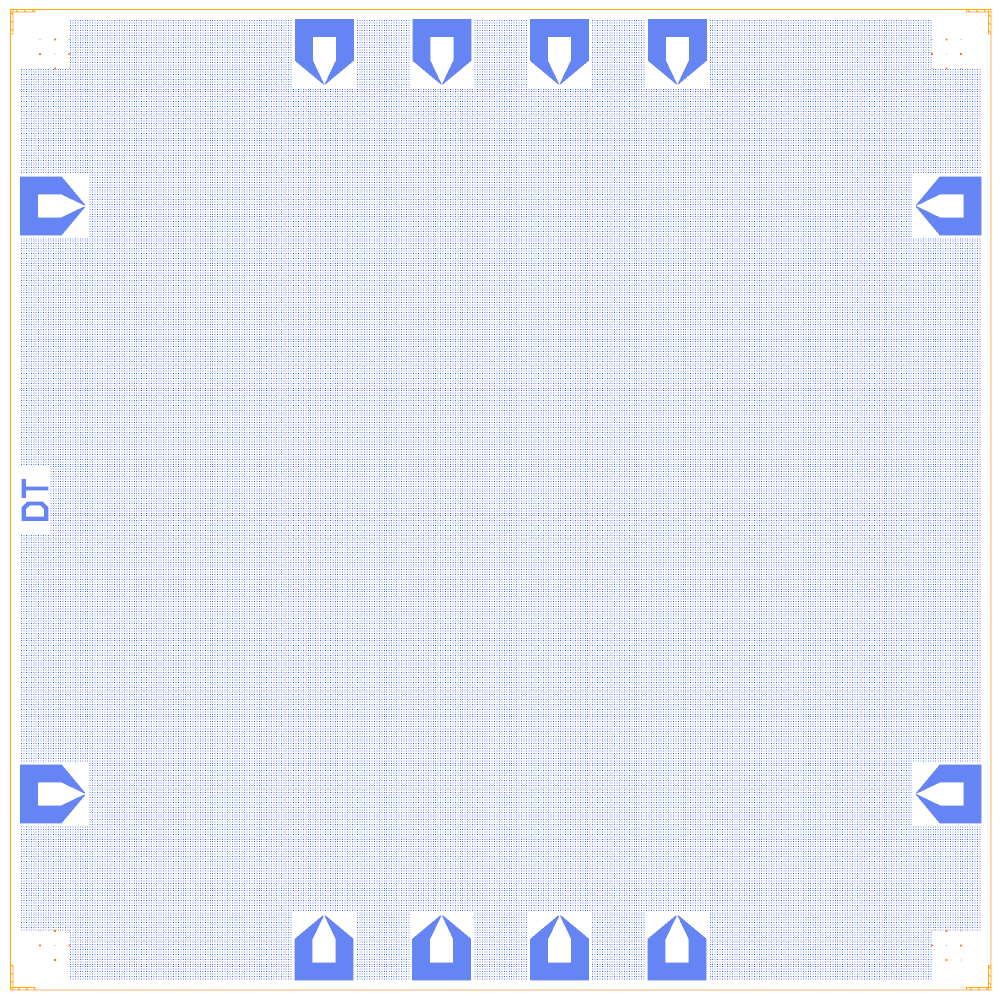

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The ARD24 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/demo_twoface/1_die.png')

In [5]:
pads = {2: "FL-QB1", 3: "PL-1-IN", 4: "PL-2-IN", 5: "FL-QB2", 7: "DL-QB2", 12: "DL-QB4", 14: "FL-QB4",
        15: "PL-2-OUT", 16: "PL-1-OUT", 17: "FL-QB3", 19: "DL-QB3", 24: "DL-QB1"}
d = Designer("demo_twoface", box=(0, 0, 10000, 10000), launchers={"type": "ARD24", "assign": pads},
             chip={"name_chip": "DT", "cheese": "chip"}, live=LIVE)
L = {name: f"chip.{name}" for name in pads.values()}       # launcher ports, "chip.<name>"
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The ARD24 launchers belong to the chip (the sample holder), not to the instances, so the"
                 " pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For ARD24 the
Designer sets `launcher_indent` = 100 + 240 (taper) + 240 (pad) + 179 (gap) = **759 µm** (KQC: 680). All routes
from launchers (Designs 4 and 7) take their waypoints from the launcher ports (`corner(L[...])`), so the 79 µm shift carries
through without other changes.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.FL-QB1 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB2 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB2 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB4 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB4 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB3 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB3 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB1 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |

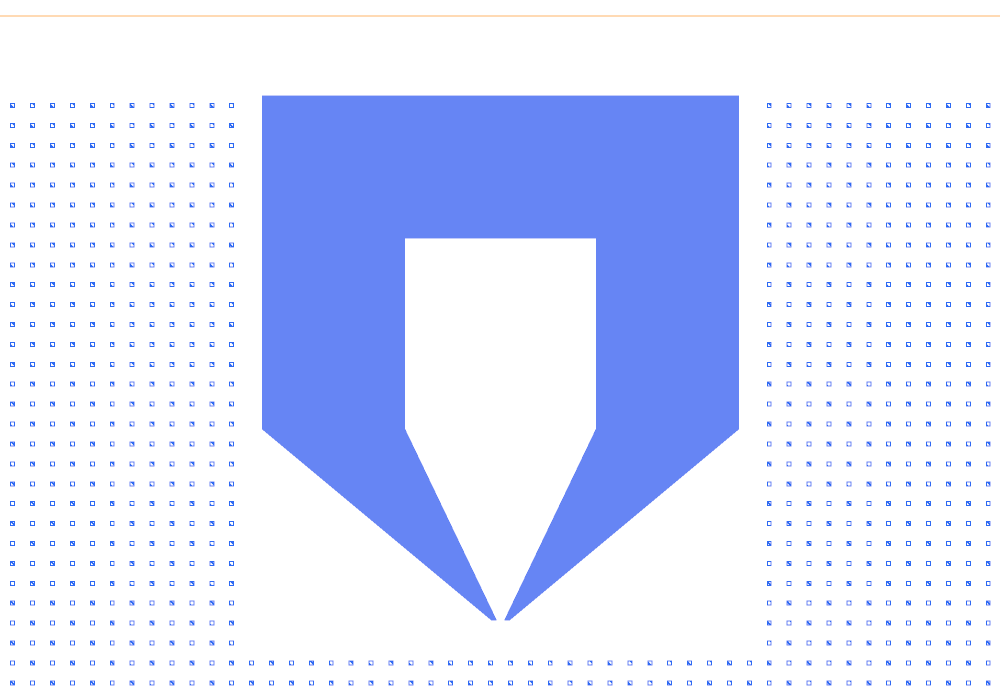

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, L["PL-1-IN"])
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## Design 3 · Qubit placement: four detuned Swissmons (before the readout line)

**The junctions from the PDK rule.** KQC draws a SQUID in every Swissmon; here each becomes a Quantcore trilayer
SQUID whose straight finger is KQC's `junction_width` (bent finger 0.6 µm). The four qubits are **detuned** by
their straight fingers (0.27 … 0.24 µm), so the two bus-coupled pairs do not hybridise; all four parallel R_n are
in the 40–50 kΩ window. `junction_from_fingers` gives each SQUID's L_J and C_J for the LOM and the FEM ports.
`TOP` puts an element on the top chip (face 1, `2b1`).

**Qubits (bottom chip).** Four `Swissmon`s at KQC's `DTrans(0, True, 2000, 6800)`, `DTrans(2, False, 8000,
6800)`, …: three 120 µm couplers, port widths 4/10/4 µm, the standard flux line. Ports `cplr0`–`cplr2`, `drive`,
`flux`.

The first picture is the chip so far, the second zooms on QB1 (no rebuild: the same build).

In [7]:
WIDTHS = {"QB1": 0.27, "QB2": 0.26, "QB3": 0.25, "QB4": 0.24}
JJ_PARAMS = {n: {"junction_type": "Quantcore Squid", "junction_width": w} for n, w in WIDTHS.items()}
JUNCTION = {n: {"Lj_nH": round(j.lj_nH, 4), "Cj_fF": round(j.cj_fF, 3)}
            for n, j in ((n, junction_from_fingers(w, 0.6, n=2)) for n, w in WIDTHS.items())}
TOP = {"face_ids": ["2b1", "1t1"]}                         # an element on the top chip (face 1)
display(Markdown("| qubit | straight finger (µm) | L_J (nH) | C_J (fF) |\n|---|---|---|---|\n" + "\n".join(
    f"| {n} | {WIDTHS[n]} | {j['Lj_nH']} | {j['Cj_fF']} |" for n, j in JUNCTION.items())))

| qubit | straight finger (µm) | L_J (nH) | C_J (fF) |
|---|---|---|---|
| QB1 | 0.27 | 6.2356 | 16.2 |
| QB2 | 0.26 | 6.4754 | 15.6 |
| QB3 | 0.25 | 6.7344 | 15.0 |
| QB4 | 0.24 | 7.015 | 14.4 |

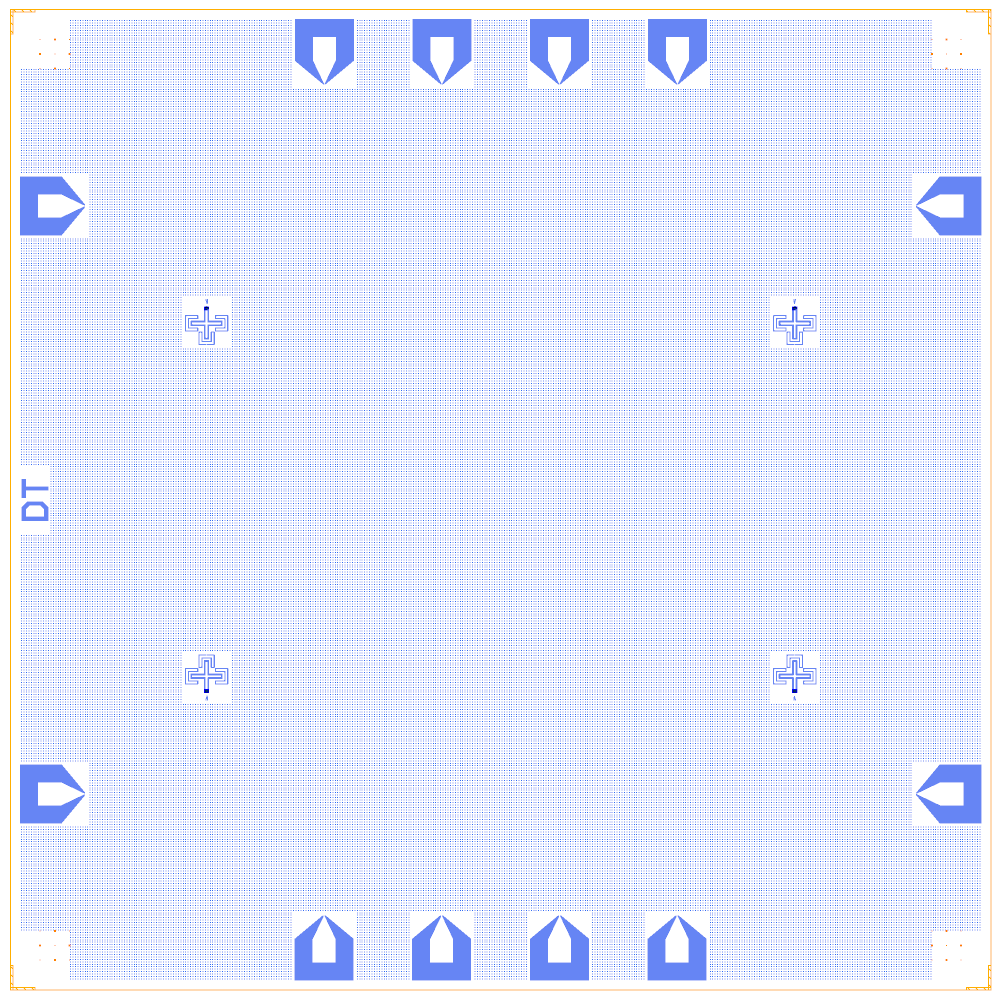

**On the chip so far:** 0 pads · 0 qubits · 4 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `QB1`, `QB2`, `QB3`, `QB4`. KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

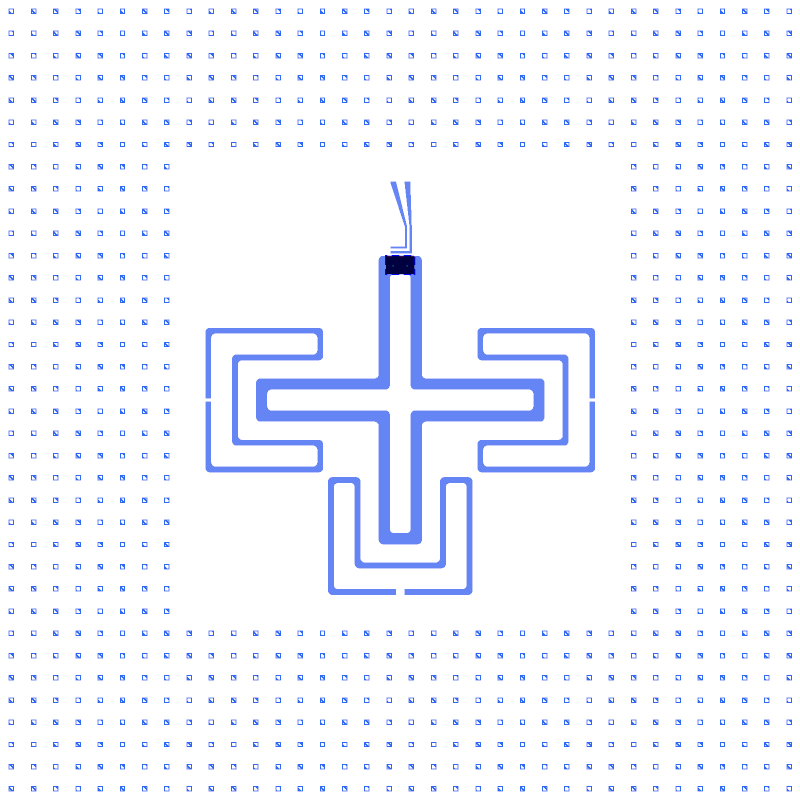

In [8]:
def xy(ref):                                     # absolute port position
    return port_xy(d, ref)


def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


base = {"QB1": (2000, 6800, 0, True), "QB2": (8000, 6800, 180, False),
        "QB3": (2000, 3200, 0, False), "QB4": (8000, 3200, 180, True)}
with d.batch():
    qb = {n: d.add(n, "Swissmon", at=(x, y), rot=r, mirror=m, cpl_length=[120, 120, 120], port_width=[4, 10, 4],
                   junction=JUNCTION[n], **JJ_PARAMS[n]) for n, (x, y, r, m) in base.items()}
layout_step(d, STEPS / "s3_qubits.png", **CHIP,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")
qx, qy = base["QB1"][:2]
snap(d, STEPS / "s3_qb1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(800, 800), width=320);

## Design 4 · Readout: the top-chip capacitors, T's and the two probe lines

**Readout capacitors and T's (top chip).** Per readout, KQC's chain: the finger capacitor (7/6/5/4 fingers)
placed by its port `a` at the meander end (700 µm out of coupler 1, then 500 µm sideways and 1300 µm further), the
probe-line T snapped by its `bottom` port to the capacitor's `b`. `add_aligned` places a cell by a port.

**Input capacitors (top chip).** A `FingerCapacitorTaper` (4 / 6 fingers, 20 µm taper) 700 µm above the first T
of each probe line.

**Probe lines** (KQC `produce_probeline("PL-1", 1, 3, mirrored=True, 4)` and `("PL-2", 2, 4, False, 6)`): from
the input launcher 1000 µm along its corner, across to the T's x, down onto the top chip (face change 700 µm
above the input capacitor) → input capacitor → T(a) → T(b) on the top chip (`face_ids=["2b1"]`) → back down to
the bottom chip and out to the launcher. Each probe line drops onto the top chip *before* it passes over a bus, as
in KQC.

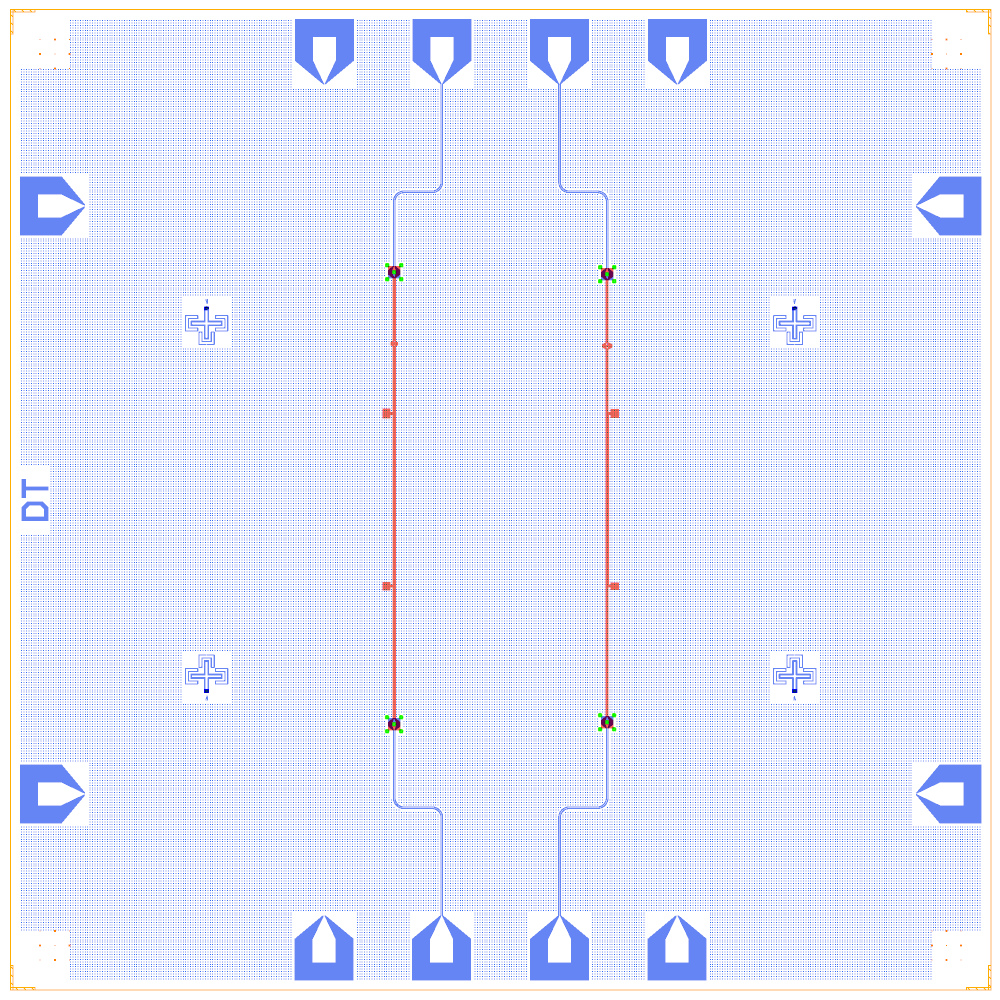

**On the chip so far:** 0 pads · 0 qubits · 14 other components · 8 routes · 0 declared couplings. **This step added** 10 component(s) `C1`, `PL1`, `C2`, `PL2`, `C3`, `PL3`, `C4`, `PL4` … (+2) and 8 route(s) `P1_in`, `P1_a`, `P1_b`, `P1_out`, `P2_in`, `P2_a`, `P2_b`, `P2_out`.

WindowsPath('build/snapshots/demo_twoface/s4_probe_lines.png')

In [9]:
RR_PATH = {}                                     # readout waypoints, used by the readouts (Design 5)
with d.batch():
    for i, mirrored, fingers in ((1, False, 7), (2, True, 6), (3, False, 5), (4, True, 4)):
        s = -1 if mirrored else 1
        p2 = shift_away(xy(f"QB{i}.cplr1"), base[f"QB{i}"][:2], 700)
        p3, p4 = (p2[0] + 400 * s, p2[1]), (p2[0] + 500 * s, p2[1])
        cap = add_aligned(d, f"C{i}", "FingerCapacitorSquare", "a", (p4[0] + 1300 * s, p4[1]),
                          rot=180 if mirrored else 0, finger_number=fingers, **TOP)
        d.add(f"PL{i}", "WaveguideCoplanarSplitter", snap="bottom", to=cap.b, lengths=[11, 11, 41],
              port_names=["right", "left", "bottom"], **TOP)
        RR_PATH[i] = (p2, p3, p4)
    for k, (qa, fingers) in enumerate(((1, 4), (2, 6)), start=1):
        lx, ly = xy(f"PL{qa}.left")
        d.add(f"CIN{k}", "FingerCapacitorTaper", at=(lx, ly + 700), rot=270, finger_number=fingers,
              taper_length=20, **TOP)                  # KQC: DTrans(3, False, T(a).left + (0, 700))
with d.batch():
    for k, (pl, qa, qbn, mirrored) in enumerate((("PL-1", 1, 3, True), ("PL-2", 2, 4, False)), start=1):
        side1, side2 = ("left", "right") if mirrored else ("right", "left")
        lx, ly = xy(f"PL{qa}.left")
        ax, ay = xy(f"CIN{k}.a")
        cx, cy = corner(L[f"{pl}-IN"])
        d.route(f"P{k}_in", L[f"{pl}-IN"], f"CIN{k}.a",
                nodes=[(cx, cy - 1000), (lx, cy - 1000), d.waypoint((ax, ay + 700), face_id="2b1")])
        d.route(f"P{k}_a", f"CIN{k}.b", f"PL{qa}.{side1}", face_ids=["2b1"])
        d.route(f"P{k}_b", f"PL{qa}.{side2}", f"PL{qbn}.{side1}", face_ids=["2b1"])
        rx, ry = xy(f"PL{qbn}.right")
        ox, oy = corner(L[f"{pl}-OUT"])
        d.route(f"P{k}_out", L[f"{pl}-OUT"], f"PL{qbn}.{side2}",
                nodes=[(ox, oy + 1000), (rx, oy + 1000), d.waypoint((rx, ry - 1400), face_id="2b1")])
layout_step(d, STEPS / "s4_probe_lines.png", **CHIP)

## Design 5 · Readout: the four λ/2 resonators, across to the top chip

**Readouts:** from coupler 1, 700 µm out, 400 µm sideways to a waypoint with `face_id="2b1"` (the face change:
KQC's `WaveguideComposite` inserts the `FlipChipConnectorRf` there), 100 µm, then a meander to the capacitor with
the KQC totals 5000 … 5300 µm. The router puts each readout's leftover length into one KQC `Meander` on the 1300 µm top-chip segment
(KQC: a `Meander` with `meanders=5` between the same two points).

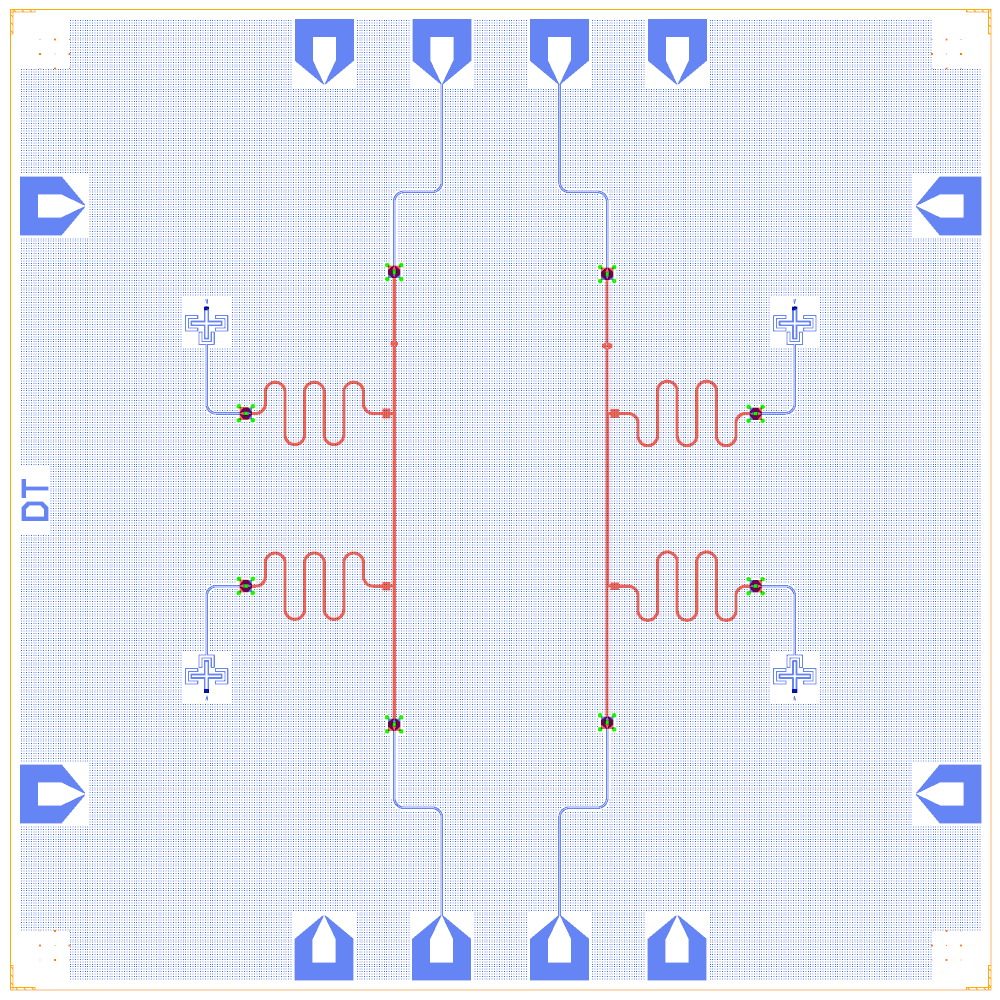

**On the chip so far:** 0 pads · 0 qubits · 14 other components · 12 routes · 0 declared couplings. **This step added** 4 route(s) `RR1`, `RR2`, `RR3`, `RR4`.

WindowsPath('build/snapshots/demo_twoface/s5_readouts.png')

In [10]:
lengths = {1: 5000, 2: 5100, 3: 5200, 4: 5300}
with d.batch():
    for i in range(1, 5):
        p2, p3, p4 = RR_PATH[i]
        d.route(f"RR{i}", qb[f"QB{i}"].cplr1, f"C{i}.a", meander=lengths[i],
                nodes=[p2, d.waypoint(p3, face_id="2b1"), p4])
layout_step(d, STEPS / "s5_readouts.png", **CHIP)

## Design 6 · Coupling: the two buses

**Buses** (a = 4, b = 9 µm) straight between the side couplers 2 of QB1–QB2 and QB4–QB3. Each joins
two side couplers into one conductor (a wire in the LOM, not a resonator): the qubits couple capacitively through it.
The probe lines cross the buses on the top chip (Design 4), so no airbridge is needed.

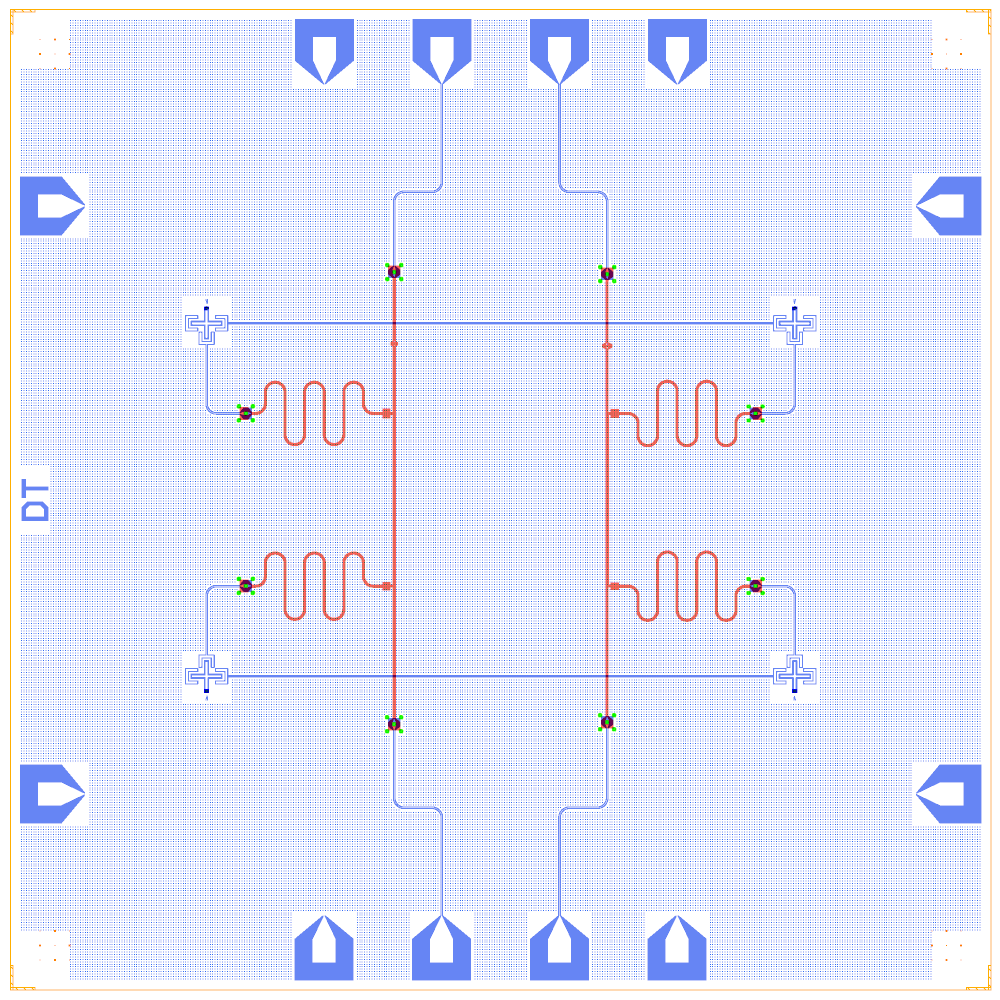

**On the chip so far:** 0 pads · 0 qubits · 14 other components · 14 routes · 0 declared couplings. **This step added** 2 route(s) `CPL12`, `CPL43`.

WindowsPath('build/snapshots/demo_twoface/s6_buses.png')

In [11]:
with d.batch():
    d.route("CPL12", qb["QB1"].cplr2, qb["QB2"].cplr2, a=4, b=9)
    d.route("CPL43", qb["QB4"].cplr2, qb["QB3"].cplr2, a=4, b=9)
layout_step(d, STEPS / "s6_buses.png", **CHIP)

## Design 7 · Routing: the charge and flux lines

**Charge lines** (6 µm
open end) from the launcher corner; **flux lines** 1500 µm past the launcher corner, then across to the qubit.

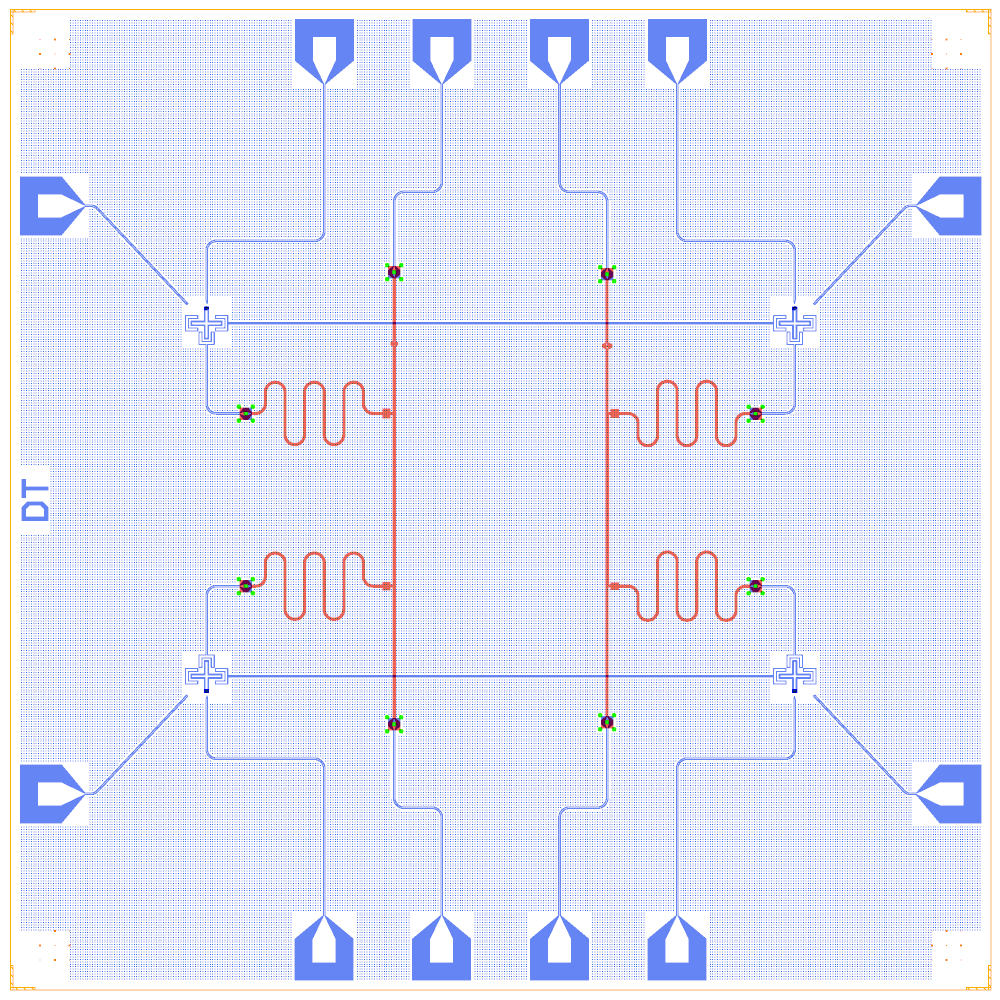

**On the chip so far:** 0 pads · 0 qubits · 14 other components · 22 routes · 0 declared couplings. **This step added** 8 route(s) `DL1`, `FL1`, `DL2`, `FL2`, `DL3`, `FL3`, `DL4`, `FL4`.

WindowsPath('build/snapshots/demo_twoface/s7_control.png')

In [12]:
with d.batch():
    for i in range(1, 5):
        d.route(f"DL{i}", L[f"DL-QB{i}"], qb[f"QB{i}"].drive, nodes=[corner(L[f"DL-QB{i}"])], term2=6)
        cx, cy = corner(L[f"FL-QB{i}"])
        shift = 1500 if i in (3, 4) else -1500
        fx, _ = xy(f"QB{i}.flux")
        d.route(f"FL{i}", L[f"FL-QB{i}"], qb[f"QB{i}"].flux, nodes=[(cx, cy + shift), (fx, cy + shift)])
layout_step(d, STEPS / "s7_control.png", **CHIP)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups, centring, save.** A Q3D C-matrix job per qubit + readout + capacitor (300 µm margin) and per bus-coupled pair. `center_in_die` confirms the content is centred (no shift); then
`demo_twoface.json` is saved with `save_design`, which compares it with the file it replaces (the previous
run's): the segments above changed how the chip is built (the routes in another order), not the chip, so it
should say *same design*; the file keeps the previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/demo_twoface.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer demo_twoface: 14 instances, 22 routes, live=False> → examples\designs\kqc\demo_twoface.json
{'P1_in': 2897.7, 'P1_a': 668.5, 'P1_b': 1740.0, 'P1_out': 3629.2, 'P2_in': 2919.7, 'P2_a': 646.5, 'P2_b': 1740.0, 'P2_out': 3629.2, 'RR1': 5000.0, 'RR2': 5100.0, 'RR3': 5200.0, 'RR4': 5300.0, 'CPL12': 5562.0, 'CPL43': 5562.0}


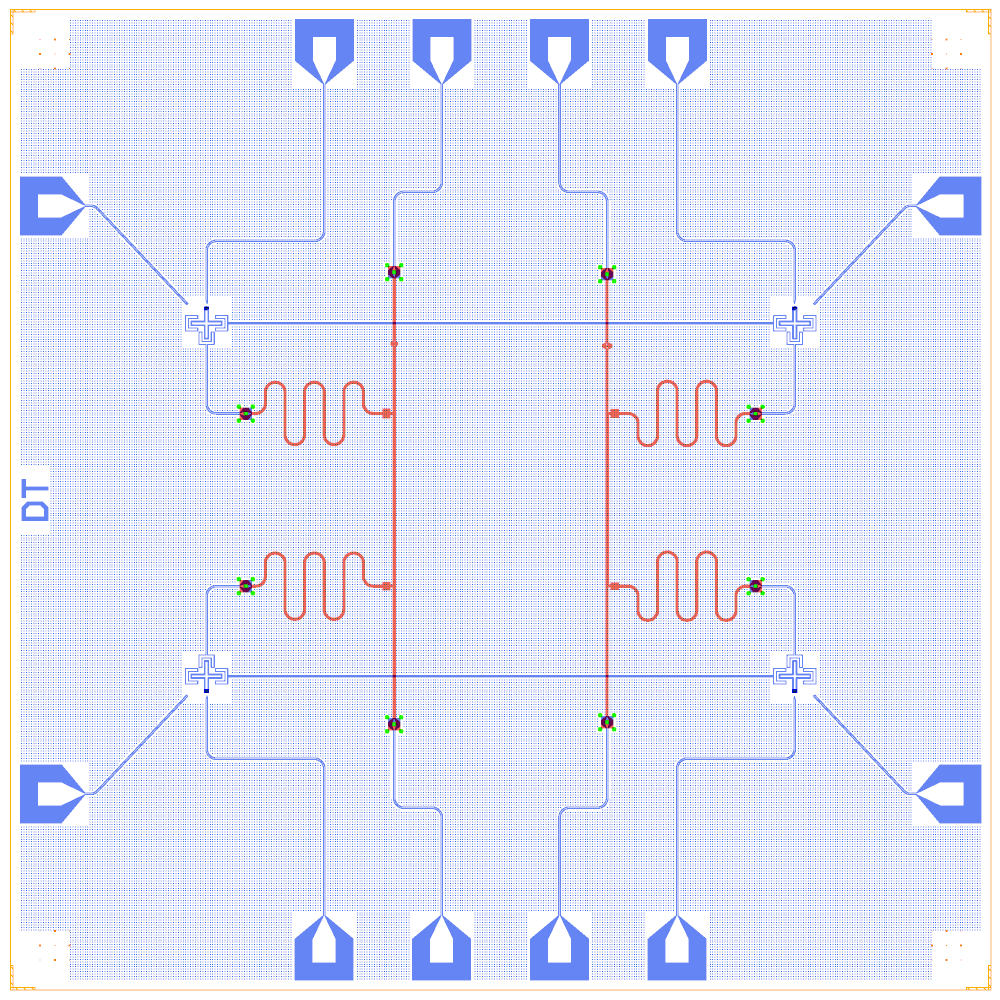

**On the chip so far:** 0 pads · 0 qubits · 14 other components · 22 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/demo_twoface/4_routes.png')

In [13]:
for i in range(1, 5):
    d.sim_group(f"QB{i}_RR{i}", [f"QB{i}", f"RR{i}", f"C{i}"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("QB1_QB2", ["QB1", "QB2", "CPL12"], analyses=["q3d_cmatrix"])
d.sim_group("QB3_QB4", ["QB3", "QB4", "CPL43"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "demo_twoface.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith(("RR", "CPL", "P"))})
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** the warnings are each Swissmon's unused coupler 0, as in KQC. **No `crossing` errors:** each probe
line drops onto the top chip (face change at the RF connector, waypoint `face_id: "2b1"`) *before* it passes over
the bottom-chip bus (CPL12 at y = 6800, CPL43 at y = 3200); the crossing rule is face-aware, so these pairs on
different faces are not flagged (the last code cells of Fab 2 check the built geometry at all four points). No PDK
design warning: `pdk_rn` applies the 40–50 kΩ window to each SQUID's parallel R_n (41.7–46.9 kΩ).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

Swissmon → island node (C and SQUID to ground) and a node per used coupler; a straight bus between two coupler
pads is one conductor (the qubits couple capacitively through it; a wire in the LOM, not a resonator); a readout
between the coupler pad and the finger capacitor → λ/2 `TLres`; the T's and probe-line routes form one probe-line
node per line, between its input capacitor and the output launcher (50 Ω). Charge and flux lines are drive /
flux controls.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB1."))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its readout, capacitor and whole probe line (input capacitor, both T's, the four routes): the
QuTiP-dressed f_q, α, f_r, κ, χ. Then each bus-coupled pair with its bus (two qubit modes, the static ZZ between
them). Expected with the detuned PDK SQUIDs (from the v1 run): f_q ≈ 6.0 / 5.9 / 5.8 / 5.7 GHz (KQC's assumed 15–18 nH gave
≈ 4.1–3.7 GHz), λ/2 readouts ≈ 11–12 GHz; the pairs are detuned by ≈ 0.1–0.2 GHz, so their modes stay
separate and ZZ is defined.

In [ ]:
groups = {}
for i, (k, qa, qbn) in ((1, (1, 1, 3)), (3, (1, 1, 3)), (2, (2, 2, 4)), (4, (2, 2, 4))):
    probe = [f"CIN{k}", f"PL{qa}", f"PL{qbn}"] + [f"P{k}_{s}" for s in ("in", "a", "b", "out")]
    groups[f"QB{i}+RR{i}"] = [f"QB{i}", f"RR{i}", f"C{i}"] + probe
results = simulate_groups(d, groups)
display(Markdown(groups_md(results)))

In [ ]:
PAIRS = {"QB1+QB2+CPL12": ["QB1", "QB2", "CPL12"], "QB3+QB4+CPL43": ["QB3", "QB4", "CPL43"]}
pairs = simulate_groups(d, PAIRS, max_modes=3)
for g, r in pairs.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pairs)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit–readout group and of the two bus-coupled pairs
(QuCat; circles are qubits, squares the readouts; filled markers are the QuTiP dressed values), (b) the dispersive
shift |χ| of each readout. The detuning plan shows in (a): four qubit frequencies ≈ 0.1 GHz apart (from the v1 run).

In [ ]:
plot_lom({**results, **pairs}, STEPS / "lom.png", title="demo_twoface: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The junction is the qubit's main frequency knob — and the detuning plan is why the pairs stay separate. Give
QB1 QB2's straight finger (0.27 → 0.26 µm: L_J 6.24 → 6.48 nH, R_n 41.7 → 43.3 kΩ): QB1 and QB2 become identical
(mirrored copies with the same capacitances), their two modes hybridise over both junctions through the bus,
and the per-pair static ZZ is no longer defined. The change is made on a copy (`design_copy`), so
`demo_twoface.json` keeps the detuning.

In [ ]:
d2 = design_copy(DESIGN)
j = junction_from_fingers(0.26, 0.6, n=2)
d2["QB1"].set(junction_width=0.26, junction={"Lj_nH": round(j.lj_nH, 4), "Cj_fF": round(j.cj_fF, 3)})
after = simulate_groups(d2, {"QB1+QB2+CPL12": PAIRS["QB1+QB2+CPL12"]}, max_modes=3)


def pair_row(r):                                 # QuCat modes of the pair: f per label, junction participations
    return {m.label: (m.f_GHz, ", ".join(f"{k} {v:.2f}" for k, v in m.participation.items() if v > 0.05))
            for m in r.modes if m.kind == "qubit"}


b, a = pair_row(pairs["QB1+QB2+CPL12"]), pair_row(after["QB1+QB2+CPL12"])
rows = [f"| {k} | {b[k][0]:.4f} · {b[k][1]} | {a[k][0]:.4f} · {a[k][1]} |" for k in sorted(set(a) & set(b))]
display(Markdown("**QB1 straight finger 0.27 → 0.26 µm (= QB2)**\n\n"
                 "| mode | before: f (GHz) · participation | after: f (GHz) · participation |\n|---|---|---|\n"
                 + "\n".join(rows)))
display(Markdown("**Static ZZ before → after:**\n\n"
                 + zz_md({"before": pairs["QB1+QB2+CPL12"], "after": after["QB1+QB2+CPL12"]})))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one Q3D job per qubit + readout and one per bus-coupled pair. The FEM exports simulate one face: the sim-group boxes hold the bottom chip (`1t1`) only, and the export notes say
so ("the flip-chip top face (2b1) is not simulated", Fab 1): a qubit's readout is in its box up to the face change, and its top-chip capacitor, T and probe line are not. The bus-coupled pairs lie wholly on the bottom chip. The sim groups ask for Q3D only; `QB1_QB2` is also exported in eigenmode (Simulate 3): `build_simulation` exports any analysis for a sim group, so the design file stays as it is.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group (their own analysis)
jobs_eig = export_sims(DESIGN, ["QB1_QB2"], analysis="eigenmode_epr")   # the bus-coupled pair in eigenmode
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

Per qubit group: the island, coupler 1 with the bottom-chip part of its readout, and the lines the box cuts (bus,
charge line) as named nets; per pair: both islands, the two side couplers the bus joins and the cut lines. Each net is
named after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `QB1_QB2` box (both qubits and the bus CPL12, all on the bottom chip) in HFSS eigenmode: each SQUID is a lumped
L_J ‖ C_J sheet, the lines the box cuts (charge, flux and readout lines) end in 50 Ω. pyEPR (run inside qcc's own
AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the two junctions' participations into the dressed f_q and α of
both qubits and their cross-Kerr (the static ZZ of the pair).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run: not here

A driven run would read the readouts' notches on the probe lines, and both run on the top chip, which the one-face
export leaves out (Simulate 1); a qubit group's box ends its readout at the face change. So no driven job is set up
for this chip: the full-wave step (`driven_from_eigenmode`, the eigenmode job's mesh seeds and frequency) applies once
the export simulates both faces (see the log's requests). The eigenmode of the pair (Simulate 3) is the FEM check of
the coupling.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {q: pairs["QB1+QB2+CPL12"].params.get(f"{q}.f_q_GHz") for q in ("QB1", "QB2")}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: each qubit's mode is the one its own SQUID participates in most; f_q is pyEPR's
dressed frequency, α its self-Kerr, and `QB1-QB2.zz_MHz` the cross-Kerr between the two qubit modes (the pair has no
readout in this box: the placeholder `_` is dropped).

In [ ]:
fem_values = {}
if keep_eig["QB1_QB2"]:
    vals = epr_values(keep_eig["QB1_QB2"], {"QB1": "_", "QB2": "_"}, {"_": 0.0})   # "_": no readout in this box
    fem_values = {k: x for k, x in vals.items() if not k.startswith("_.") and k != "modes"}
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n"
                     + "\n".join(f"| `{k}` | {x:.5g} |" for k, x in fem_values.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of QB1 and QB2 and their "
          "cross-Kerr from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** per bus-coupled pair, `fill` replaces the capacitance estimates of its group by the
C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM runs again. **FEM
directly:** the eigenmode (pyEPR) values of Results 2, with |ZZ| next to the LOM's static ZZ (the two codes may sign
it differently). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate


def zz_of(r, pair):                              # the LOM's static ZZ of a pair (MHz), None if hybridised
    return next((z["zz_MHz"] for z in r.dressed.get("zz", []) if z["pair"] == pair and not z["hybridised"]), None)


rows = []
for g, sg, qa, qbn in (("QB1+QB2+CPL12", "QB1_QB2", "QB1", "QB2"), ("QB3+QB4+CPL43", "QB3_QB4", "QB3", "QB4")):
    est = pairs[g].params
    keys = [f"{qa}.f_q_GHz", f"{qa}.alpha_MHz", f"{qbn}.f_q_GHz", f"{qbn}.alpha_MHz"]
    if keep_q3d.get(sg):
        on_fem = simulate(fill(d.lom(select=PAIRS[g]).model, DESIGN, keep_q3d[sg]), max_modes=3)
        rows += [(key, est.get(key), on_fem.params.get(key), "LOM on the Q3D C-matrix") for key in keys]
    if sg == "QB1_QB2" and fem_values:
        rows += [(key, est.get(key), fem_values[key], "eigenmode + pyEPR") for key in keys if key in fem_values]
        zz_l, zz_f = zz_of(pairs[g], "QB1-QB2"), fem_values.get("QB1-QB2.zz_MHz")
        if zz_l is not None and zz_f is not None:
            rows.append(("QB1-QB2 |ZZ| (MHz)", abs(zz_l), abs(zz_f), "eigenmode cross-Kerr"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts each pair's f_q and α of the LOM next to the LOM "
          "on the Q3D C-matrix, and QB1 / QB2 next to the eigenmode (with |ZZ|), with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `DemoTwoface` states no frequencies, so this notebook sets one as an exercise: **QB2 at 5.86 GHz**, so that it
sits 150 MHz below its bus partner QB1 instead of ≈ 100 MHz (from the v1 run: QB1 6.012, QB2 5.913 GHz). LOM 3 shows
what an equal pair does (the modes hybridise); a wider detuning is more margin against the junctions' spread. It is
reachable inside the PDK junction window: QB2's L_J goes from 6.48 nH to ≈ 6.59 nH, R_n ≈ 44 kΩ (`pdk_lj_bounds`
keeps the feedback within 40–50 kΩ). The readouts are not targeted.

The targets go on a copy (`target_copy` → `build/demo_twoface_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; the drawn SQUID keeps its 0.26 µm straight fingers until it is sized again with
`trilayer_junction(..., lj_nH=..., squid=True)`. If the consensus table is empty, `loop.analyse` found no
qubit–readout pair it can tune here (see the log's requests): the cell then says so instead of proposing knobs.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"QB2": {"f_q_GHz": 5.86}}   # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
the target is inside its tolerance or `MAX_ITER` revisions are made (`build/demo_twoface/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's QB1_QB2 Q3D job is exported and solved first (`solve_rev`), so the
loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value against the target
and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ('QB1_QB2',)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `demo_twoface.json` is the whole design: `qcc build examples/designs/kqc/demo_twoface.json`
rebuilds `build/demo_twoface.oas` + sidecar.

**The fab mask.** `export_fab` writes the PDK fab layers: bottom chip base etch 1/0 (with the cheese: source `build`, the PDK cheese over the whole bottom chip, 137 290 holes in a probe), the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every cheese hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0, the frame
(100/0, 1000/0, 1001/0); the top chip (face 2b1) goes to 800/0 (etch), 801/0 (indium bumps) and 802/0 (UBM).
Corner rounding is skipped unless `FULL_FAB`; `qcc mask examples/designs/kqc/demo_twoface.json` writes the
complete file.

**Simulation export options.** No cheese in simulation exports; airbridges dropped unless `airbridges=True`;
`setup.geometry` reports what was left out.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB1_RR1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

Full chip (both faces drawn); QB1; its SQUID; the QB1 readout's face change (RF connector); its finger capacitor
and T on the top chip; one of the four places where a probe line passes over a bus; the die frame's south-west
corner; QB1 in the **fab view** (the mask from Fab 1: 1/0 with the PDK cheese holes, 3/0, the trilayer layers); and
KQC's own `DemoTwoface` built stand-alone. (The layout snapshots show the bottom chip's PDK cheese, a light, even texture at full-chip scale, and draw the chip boundary 100/0 as an outline; the fab view shows the cheese holes on 1/0 and 3/0.)

In [ ]:
show_snapshot(d, OUT / "demo_twoface.png", box=(-100, -100, 10100, 10100))   # chip only (KQC launcher names outside)
qx, qy = base["QB1"][:2]
show_snapshot(d, OUT / "demo_twoface_qb1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), width=420)
show_snapshot(d, OUT / "demo_twoface_squid.png", box=(qx - 60, qy + 100, qx + 60, qy + 220), width=360)
x2, y2 = shift_away(xy("QB1.cplr1"), (qx, qy), 700)
show_snapshot(d, OUT / "demo_twoface_connector.png", box=(x2 + 200, y2 - 200, x2 + 600, y2 + 200), width=360)
cx, cy = xy("C1.b")
show_snapshot(d, OUT / "demo_twoface_coupler.png", box=(cx - 150, cy - 150, cx + 150, cy + 150), width=360)
show_snapshot(d, OUT / "demo_twoface_crossing.png", box=(3814, 6700, 4014, 6900), width=360)   # P1_in (top chip) over CPL12
show_snapshot(d, OUT / "demo_twoface_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "demo_twoface_fab.oas", OUT / "demo_twoface_fab_qb1.png",
          box=(qx - 250, qy - 250, qx + 250, qy + 250), size=(1200, 1200), width=420);

**The four bus crossings in the built geometry:** the probe line is on the top chip (2b1 gaps) and the bus
centre conductor on 1t1 is not cut (zero 1t1 gap area within ±2 µm of the bus centre line).

In [ ]:
import klayout.db as kdb
ly = kdb.Layout(); ly.read(str(d.out)); top_d = ly.top_cell()
gap = {f: kdb.Region(top_d.begin_shapes_rec(next(i for i in ly.layer_indexes()
                                               if ly.get_info(i).name == f"{f}_base_metal_gap_wo_grid")))
       for f in ("1t1", "2b1")}
rows = ["| crossing (x, y) | 1t1 gap within ±2 µm of the bus centre (µm²) | 2b1 gap there (µm², the probe line) |",
        "|---|---|---|"]
for x, y in ((3914, 6800), (6086, 6800), (3914, 3200), (6086, 3200)):
    box = kdb.Region(kdb.Box(int((x - 30) / ly.dbu), int((y - 2) / ly.dbu), int((x + 30) / ly.dbu), int((y + 2) / ly.dbu)))
    rows.append(f"| ({x}, {y}) | {(gap['1t1'] & box).area() * ly.dbu ** 2:.0f} | {(gap['2b1'] & box).area() * ly.dbu ** 2:.0f} |")
display(Markdown("\n".join(rows)))

In [ ]:
from kqcircuits.chips.demo_twoface import DemoTwoface
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_demo_twoface")
top.insert(pya.DCellInstArray(DemoTwoface.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "demo_twoface_kqc_original.oas"))
snap_file(Path("build") / "demo_twoface_kqc_original.oas", OUT / "demo_twoface_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## Summary

| | |
|---|---|
| **matches the source** | every KQC element on both faces with its parameters, positions and orientations; the ARD24 launcher assignment; every route's path including the face changes and RF connectors; readout lengths 5000–5300 µm; the sim groups; the whole-area cheese coverage of the bottom chip (with the PDK squares instead of KQC's grid) |
| **differs (PDK)** | Quantcore die frame on the bottom chip (none on the top chip: PDK v3 has no top-chip frame); launchers 79 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire; detuned Quantcore trilayer SQUIDs (f_q ≈ 6.0–5.7 GHz instead of ≈ 4.1–3.7 GHz); no cheese on the top chip |
| **simplified** | router-fitted readout meanders |
| **PDK design warnings** | none (parallel R_n 41.7–46.9 kΩ; f_q 5.7–6.0 GHz) |
| **FEM** | 6 Q3D jobs and the QB1_QB2 eigenmode job exported (`build/jobs/demo_twoface_*`), not solved here; one face only (the top chip is not simulated), so no driven run |
| layout | built in eight segments (die and launchers, the launcher check, the qubits — before the readout line, whose parts are placed from their ports —, the top-chip readout line, the readouts, the buses, the charge and flux lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (QB2 5.86 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; a two-face export (the top chip) for the readouts and the driven run; the revision's drawn SQUID keeps its fingers |